# N4 — Model Architecture: ECGCNNBiLSTM

**Purpose:** Build, inspect, and validate the `ECGCNNBiLSTM` model architecture.

**What this notebook covers:**
1. Instantiate the model and print layer-by-layer structure
2. Trace tensor shapes through each stage (CNN → BiLSTM → Head)
3. Count parameters per stage
4. Verify forward pass on random inputs
5. Visualise CNN feature maps on a real ECG window

**Linked module:** `Modules/model.py`

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / 'Modules'))

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

import config
from model import ECGCNNBiLSTM, ConvBlock, build_model

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

Device: cpu


In [2]:
# ---- Build model and print structure ----
model = build_model(DEVICE)
print(model)
print(f'\nTotal trainable parameters: {model.count_parameters():,}')

ECGCNNBiLSTM(
  (cnn): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv1d(1, 32, kernel_size=(15,), stride=(2,), padding=(7,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
        (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (2): ConvBlock(
      (block): Sequential(
        (0): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
        (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool1d(k

In [3]:
# ---- Parameter count per stage ----
cnn_params = sum(p.numel() for p in model.cnn.parameters())
lstm_params = sum(p.numel() for p in model.lstm.parameters())
clf_params  = sum(p.numel() for p in model.classifier.parameters())
total       = model.count_parameters()

print(f'CNN feature extractor : {cnn_params:>8,} params ({100*cnn_params/total:.1f}%)')
print(f'BiLSTM                : {lstm_params:>8,} params ({100*lstm_params/total:.1f}%)')
print(f'Classifier head       : {clf_params:>8,}  params ({100*clf_params/total:.1f}%)')
print(f'Total                 : {total:>8,} params')

CNN feature extractor :  105,984 params (13.5%)
BiLSTM                :  659,456 params (84.3%)
Classifier head       :   16,773  params (2.1%)
Total                 :  782,213 params


In [4]:
# ---- Trace tensor shapes through each stage ----
B = 4  # batch size for this test
x = torch.randn(B, 1, config.WINDOW_SAMPLES, device=DEVICE)
print(f'Input:                {tuple(x.shape)}')

model.eval()
with torch.no_grad():
    # CNN stages individually
    x_cnn = x
    for i, block in enumerate(model.cnn):
        x_cnn = block(x_cnn)
        print(f'After ConvBlock {i+1}:    {tuple(x_cnn.shape)}')
    
    # Permute for LSTM
    lstm_in = x_cnn.permute(0, 2, 1)
    print(f'\nAfter permute (LSTM in): {tuple(lstm_in.shape)}')
    
    # LSTM
    lstm_out, _ = model.lstm(lstm_in)
    print(f'LSTM output:          {tuple(lstm_out.shape)}')
    
    # Global avg pool
    pooled = lstm_out.mean(dim=1)
    print(f'After global avg pool:{tuple(pooled.shape)}')
    
    # Classifier
    logits = model.classifier(pooled)
    print(f'Logits (output):      {tuple(logits.shape)}')

print(f'\nExpected output shape: ({B}, {config.NUM_CLASSES})')
assert logits.shape == (B, config.NUM_CLASSES), 'Shape mismatch!'
print('PASS: All shapes correct.')

Input:                (4, 1, 2500)
After ConvBlock 1:    (4, 32, 625)
After ConvBlock 2:    (4, 64, 312)
After ConvBlock 3:    (4, 128, 156)
After ConvBlock 4:    (4, 128, 78)

After permute (LSTM in): (4, 78, 128)
LSTM output:          (4, 78, 256)
After global avg pool:(4, 256)
Logits (output):      (4, 5)

Expected output shape: (4, 5)
PASS: All shapes correct.


In [5]:
# ---- Verify outputs are reasonable raw logits (not probabilities) ----
logits_np = logits.cpu().numpy()
probs = torch.softmax(logits, dim=1).cpu().numpy()

print('Sample logits (first 2 items in batch):')
print(logits_np[:2])
print('\nSoftmax probabilities:')
print(probs[:2])
print(f'\nProb row sums: {probs.sum(axis=1)}')  # should all be ~1.0

# Prediction with random weights should be roughly uniform
print(f'\nPredicted classes: {logits_np.argmax(axis=1)}')

Sample logits (first 2 items in batch):
[[ 0.03079123  0.09964684 -0.03327146  0.05147275 -0.08825325]
 [ 0.03083711  0.09974404 -0.03324082  0.05157628 -0.08828352]]

Softmax probabilities:
[[0.20333911 0.21783344 0.19072115 0.20758827 0.18051803]
 [0.20333782 0.21784322 0.19071701 0.20759891 0.18050313]]

Prob row sums: [1.        1.0000001 1.        1.       ]

Predicted classes: [1 1 1 1]


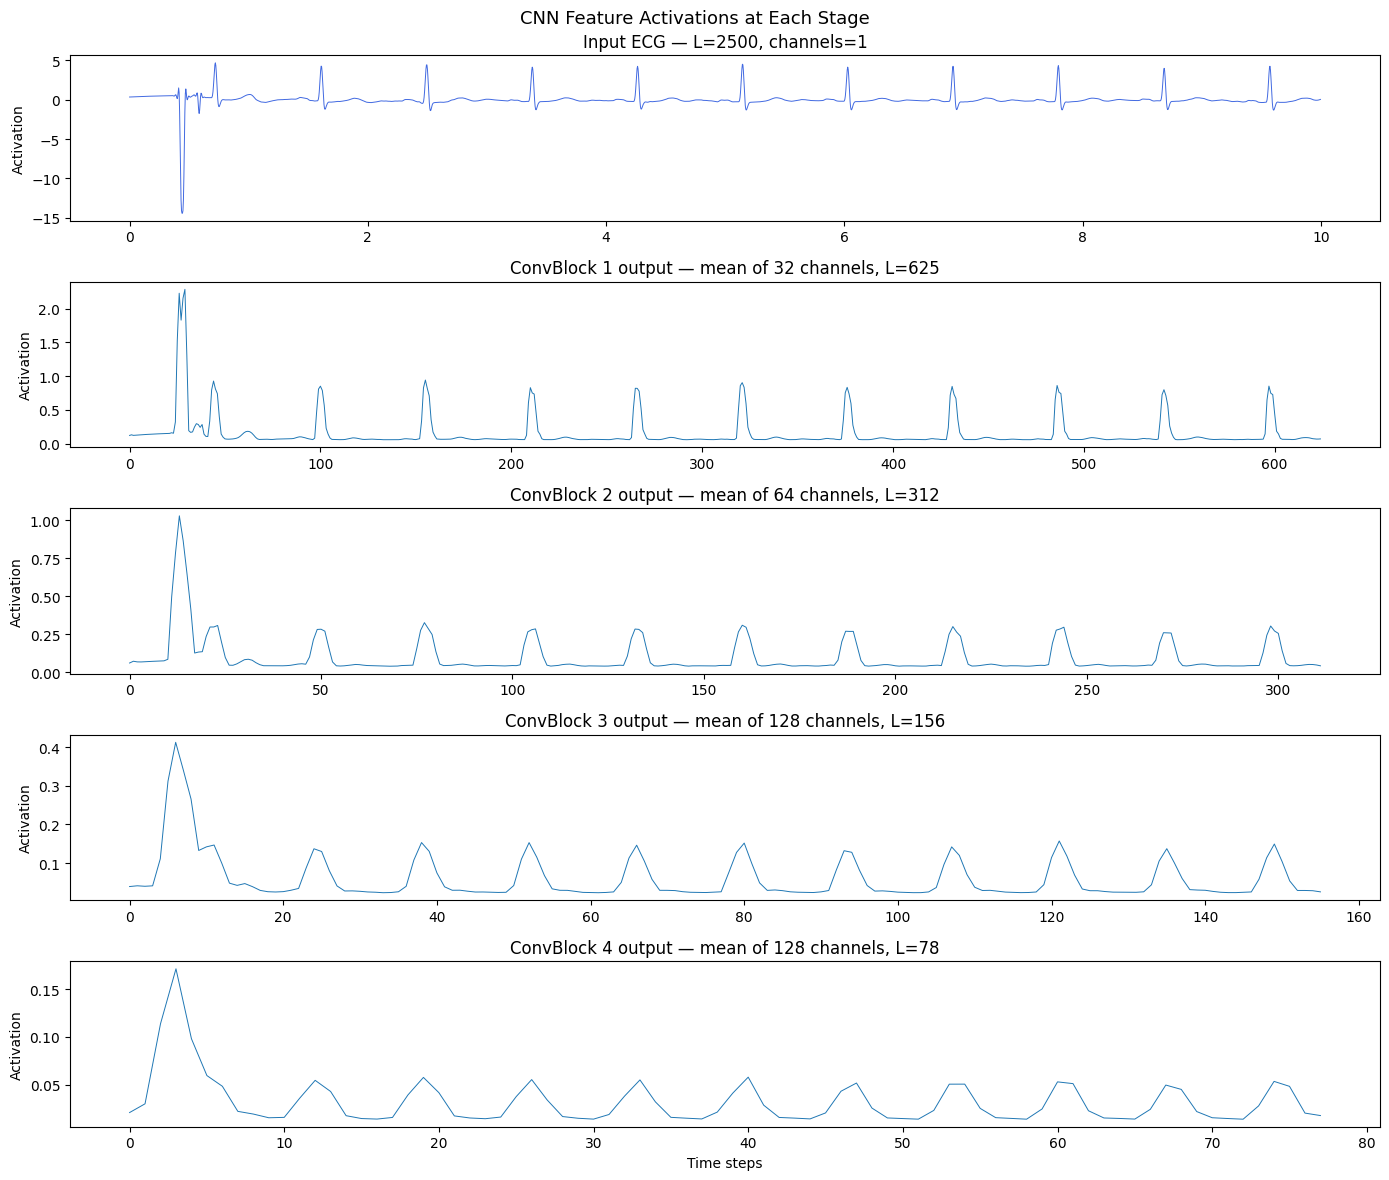

In [6]:
# ---- Visualise CNN feature maps on a real preprocessed ECG window ----
try:
    import vitaldb
    from preprocessing import preprocess_ecg_window

    vals = vitaldb.load_case(337, ['SNUADC/ECG_II'], 1/config.SOURCE_FS)
    raw_win = vals[:int(10 * config.SOURCE_FS), 0]  # first 10s, 5000 samples
    processed = preprocess_ecg_window(raw_win)       # (2500,) float32
    
    x_real = torch.from_numpy(processed).unsqueeze(0).unsqueeze(0).to(DEVICE)  # (1,1,2500)

    model.eval()
    with torch.no_grad():
        # Extract features after each CNN block
        acts = [x_real]
        for block in model.cnn:
            acts.append(block(acts[-1]))

    fig, axes = plt.subplots(5, 1, figsize=(14, 12))
    for i, (act, ax) in enumerate(zip(acts, axes)):
        a = act[0].cpu().numpy()  # (channels, L)
        if i == 0:
            t = np.arange(a.shape[-1]) / config.TARGET_FS
            ax.plot(t, a[0], lw=0.7, color='royalblue')
            ax.set_title(f'Input ECG — L={a.shape[-1]}, channels=1')
        else:
            # Show mean activation across all channels
            t = np.arange(a.shape[-1])
            ax.plot(t, a.mean(axis=0), lw=0.7)
            ax.set_title(f'ConvBlock {i} output — mean of {a.shape[0]} channels, L={a.shape[-1]}')
        ax.set_ylabel('Activation')

    axes[-1].set_xlabel('Time steps')
    plt.suptitle('CNN Feature Activations at Each Stage', fontsize=13)
    plt.tight_layout()
    plt.show()
    
except Exception as e:
    print(f'Skipped feature map visualisation: {e}')